# ML Project 1: MICHD prediction (BRFSS)
Team CouscousAI.
This notebook contains the whole project: data exploration, preprocessing, the six methods from class, cross-validation, the improvements we tried, the ablation studies and the final submission. The figures used in the report are saved in `report_figures/`.

In [1]:
import os
import sys
import gc

project_dir = r"C:\Users\chebi\Desktop\ml-project1"
if os.path.isdir(project_dir):
    os.chdir(project_dir)
sys.path.insert(0, os.getcwd())

from helpers import load_csv_data, create_csv_submission
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import implementations as impl

SEED = 42
DATA_PATH = os.environ.get("MICHD_DATA_PATH", "dataset/")
K_FOLDS = 3

INK, MUTED, GRID = "#1f2328", "#57606a", "#d8dee4"
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update(
    {
        "figure.dpi": 200,
        "font.size": 7.5,
        "axes.titlesize": 7.5,
        "axes.labelsize": 7.5,
        "xtick.labelsize": 6.5,
        "ytick.labelsize": 6.5,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.family": "serif",
        "pdf.fonttype": 42,
    }
)
FIG_DIR = "report_figures"
os.makedirs(FIG_DIR, exist_ok=True)


def save_and_show(fig, name):
    fig.tight_layout(pad=0.2)
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight", pad_inches=0.02)
    plt.show()


def errorbar(ax, xs, means, stds):
    ax.errorbar(xs, means, yerr=stds, color=BLUE, linewidth=1.5, marker="o",
                markersize=3, capsize=2, elinewidth=0.8)

## Load the data

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

with open(os.path.join(DATA_PATH, "x_train.csv")) as f:
    feature_names = f.readline().strip().split(",")[1:]

print("shapes:", x_train.shape, y_train.shape, x_test.shape)
print("classes:", np.unique(y_train, return_counts=True))
print("total NaNs:", np.isnan(x_train).sum(), f"({np.isnan(x_train).mean():.1%} of all entries)")
print("fraction of rows with at least one NaN:", np.isnan(x_train).any(axis=1).mean())

y01 = (y_train == 1).astype(float)

shapes: (328135, 321) (328135,) (109379, 321)
classes: (array([-1,  1]), array([299160,  28975], dtype=int64))
total NaNs: 47175779 (44.8% of all entries)
fraction of rows with at least one NaN: 1.0


## Train / validation split

In [3]:
def train_val_split(x, y, ratio=0.8, seed=SEED):
    num_row = y.shape[0]
    interval = int(num_row * ratio)
    rng = np.random.RandomState(seed)
    indices = rng.permutation(num_row)

    train_indices = indices[:interval]
    val_indices = indices[interval:]
    return x[train_indices], x[val_indices], y[train_indices], y[val_indices]


def stratified_split(x, y, ratio=0.8, seed=SEED):
    rng = np.random.RandomState(seed)
    train_parts, val_parts = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        cut = int(len(idx) * ratio)
        train_parts.append(idx[:cut])
        val_parts.append(idx[cut:])
    train_indices = rng.permutation(np.concatenate(train_parts))
    val_indices = rng.permutation(np.concatenate(val_parts))
    return x[train_indices], x[val_indices], y[train_indices], y[val_indices]

In [4]:
_, _, y_tr_rand, y_val_rand = train_val_split(x_train, y01)
print("random split     -> pos rate train:", y_tr_rand.mean(), "| val:", y_val_rand.mean())

x_tr, x_val, y_tr, y_val = stratified_split(x_train, y01)
print("stratified split -> pos rate train:", y_tr.mean(), "| val:", y_val.mean())

random split     -> pos rate train: 0.08790208298413762 | val: 0.0899020220336142
stratified split -> pos rate train: 0.08830207079403295 | val: 0.08830207079403295


## Exploratory data analysis

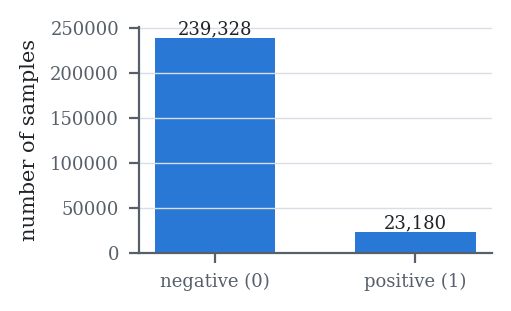

{0.0: 239328, 1.0: 23180}
Positive rate: 0.08830207079403295


In [5]:
classes, counts = np.unique(y_tr, return_counts=True)

fig, ax = plt.subplots(figsize=(2.4, 1.4))
ax.bar(["negative (0)", "positive (1)"], counts, color=BLUE, width=0.6)
for k, c in enumerate(counts):
    ax.text(k, c, f"{c:,}", ha="center", va="bottom", fontsize=6.5, color=INK)
ax.set_ylabel("number of samples")
ax.grid(axis="x", visible=False)
save_and_show(fig, "class_balance.pdf")

print(dict(zip(classes, counts)))
print("Positive rate:", y_tr.mean())

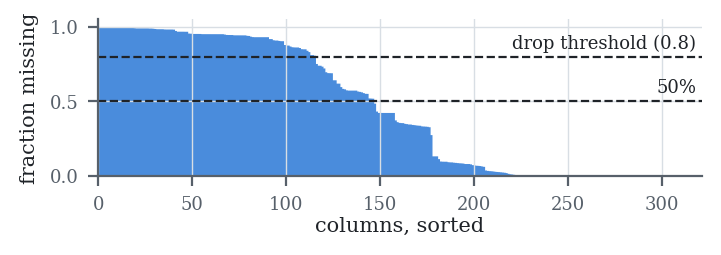

Columns above 50%: 147
Columns above 80%: 116
LADULT 0.9998971459917412
COLGHOUS 0.9998971459917412
PCDMDECN 0.9994247794352934
ASDRVIST 0.9993219254270346
ASERVIST 0.9993219254270346
ASNOSLEP 0.9989828881405519
ASINHALR 0.9986057567769363
ASTHMED3 0.9986057567769363
ASYMPTOM 0.998601947369223
ASACTLIM 0.9985981379615098


In [6]:
nan_fraction = np.isnan(x_tr).mean(axis=0)
order = np.argsort(nan_fraction)[::-1]

fig, ax = plt.subplots(figsize=(3.45, 1.12))
ax.fill_between(np.arange(len(order)), nan_fraction[order], step="mid", color=BLUE, alpha=0.85, linewidth=0)
for y, label in [(0.8, "drop threshold (0.8)"), (0.5, "50%")]:
    ax.axhline(y, color=INK, linestyle="--", linewidth=0.8)
    ax.text(len(order) - 3, y + 0.03, label, ha="right", va="bottom", fontsize=6.5, color=INK)
ax.set_xlim(0, len(order))
ax.set_ylim(0, 1.05)
ax.set_xlabel("columns, sorted", labelpad=1)
ax.set_ylabel("fraction missing")
save_and_show(fig, "nan_fraction.pdf")

print("Columns above 50%:", np.sum(nan_fraction > 0.50))
print("Columns above 80%:", np.sum(nan_fraction > 0.80))

for j in order[:10]:
    print(feature_names[j], nan_fraction[j])

Number of constant columns: 6
['CTELENUM', 'COLGHOUS', 'STATERES', 'CTELNUM1', 'CELLFON2', 'CCLGHOUS']


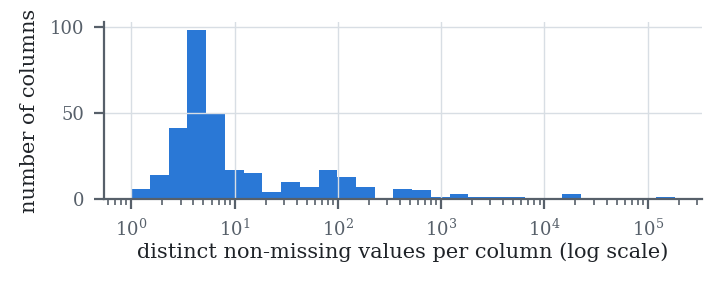

CTELNUM1 1
CCLGHOUS 1
CTELENUM 1
CELLFON2 1
COLGHOUS 1
STATERES 1
_FRTRESP 2
_VEGRESP 2
_DRDXAR1 2
_VEG23 2
CSTATE 2
PVTRESD2 2
CADULT 2
SEX 2
_FRT16 2
CELLFON3 2
PVTRESD1 2
DISPCODE 2
IYEAR 2
LADULT 2


In [7]:
n_unique = np.zeros(x_tr.shape[1], dtype=int)

for j in range(x_tr.shape[1]):
    column = x_tr[:, j]
    non_nan = column[~np.isnan(column)]
    n_unique[j] = np.unique(non_nan).size

constant_idx = np.where(n_unique <= 1)[0]

print("Number of constant columns:", len(constant_idx))
print([feature_names[j] for j in constant_idx])

fig, ax = plt.subplots(figsize=(3.45, 1.25))
ax.hist(n_unique, bins=np.logspace(0, np.log10(max(n_unique.max(), 10)), 30), color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("distinct non-missing values per column (log scale)", labelpad=1)
ax.set_ylabel("number of columns")
save_and_show(fig, "distinct_values.pdf")

for j in np.argsort(n_unique)[:20]:
    print(feature_names[j], n_unique[j])

In [8]:
metadata_names = ["_STATE", "FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "SEQNO", "_PSU", "_STSTR"]

for name in metadata_names:
    if name in feature_names:
        j = feature_names.index(name)
        print(name, "number of values:", n_unique[j])

_STATE number of values: 53
FMONTH number of values: 12
IDATE number of values: 414
IMONTH number of values: 12
IDAY number of values: 31
IYEAR number of values: 2
SEQNO number of values: 20761
_PSU number of values: 20761
_STSTR number of values: 1305


In [9]:
name_to_idx = {n: j for j, n in enumerate(feature_names)}

for name in ["PHYSHLTH", "MENTHLTH", "CHILDREN", "WEIGHT2", "HEIGHT3", "ALCDAY5", "EMPLOY1", "_RACE", "_AGEG5YR"]:
    if name not in name_to_idx:
        print(f"{name:10s} absent")
        continue
    col = x_tr[:, name_to_idx[name]]
    values, counts = np.unique(col[~np.isnan(col)], return_counts=True)
    top = np.argsort(counts)[::-1][:8]
    print(f"{name:10s} max={values.max():g}  top values:", {float(values[i]): int(counts[i]) for i in top})

PHYSHLTH   max=99  top values: {88.0: 163433, 30.0: 20235, 2.0: 14559, 1.0: 10946, 3.0: 8404, 5.0: 7371, 10.0: 5375, 15.0: 4886}
MENTHLTH   max=99  top values: {88.0: 179245, 30.0: 13093, 2.0: 12728, 5.0: 8778, 1.0: 8198, 3.0: 7297, 10.0: 6403, 15.0: 5743}
CHILDREN   max=99  top values: {88.0: 192578, 1.0: 27383, 2.0: 24339, 3.0: 10409, 4.0: 3752, 99.0: 2168, 5.0: 1203, 6.0: 426}
WEIGHT2    max=9999  top values: {200.0: 12890, 180.0: 12206, 150.0: 12017, 160.0: 11209, 9999.0: 10642, 170.0: 10275, 140.0: 8754, 190.0: 8485}
HEIGHT3    max=9999  top values: {504.0: 23549, 506.0: 23276, 505.0: 20666, 507.0: 20575, 503.0: 19087, 508.0: 18840, 502.0: 18434, 510.0: 17484}
ALCDAY5    max=999  top values: {888.0: 123505, 201.0: 20233, 202.0: 15194, 101.0: 9937, 230.0: 8689, 203.0: 8366, 102.0: 8026, 205.0: 7179}
EMPLOY1    max=9  top values: {1.0: 107226, 7.0: 78559, 2.0: 21732, 8.0: 18804, 5.0: 15993, 6.0: 6971, 3.0: 5586, 4.0: 5363}
_RACE      max=9  top values: {1.0: 200331, 8.0: 21086, 2.0:

In [10]:
positive = (y_tr == 1)
categorical_idx = np.where((n_unique > 1) & (n_unique <= 20))[0]
print(len(categorical_idx), "columns with 2-20 distinct values (only the first 15 printed)")

for j in categorical_idx[:15]:
    values, counts = np.unique(x_tr[:, j][~np.isnan(x_tr[:, j])], return_counts=True)
    print("\nFeature:", feature_names[j])
    for value, count in zip(values, counts):
        if count >= 100:
            rate = positive[x_tr[:, j] == value].mean()
            print("  value:", value, "count:", count, "positive rate:", round(rate, 4))

236 columns with 2-20 distinct values (only the first 15 printed)

Feature: FMONTH
  value: 1.0 count: 26368 positive rate: 0.086
  value: 2.0 count: 22010 positive rate: 0.085
  value: 3.0 count: 20862 positive rate: 0.0892
  value: 4.0 count: 24288 positive rate: 0.0849
  value: 5.0 count: 20032 positive rate: 0.0893
  value: 6.0 count: 19576 positive rate: 0.0899
  value: 7.0 count: 24509 positive rate: 0.0859
  value: 8.0 count: 19620 positive rate: 0.0894
  value: 9.0 count: 19772 positive rate: 0.0919
  value: 10.0 count: 25037 positive rate: 0.0852
  value: 11.0 count: 20390 positive rate: 0.0943
  value: 12.0 count: 20044 positive rate: 0.0917

Feature: IMONTH
  value: 1.0 count: 22479 positive rate: 0.0859
  value: 2.0 count: 23264 positive rate: 0.0837
  value: 3.0 count: 25169 positive rate: 0.0872
  value: 4.0 count: 21373 positive rate: 0.0877
  value: 5.0 count: 20527 positive rate: 0.0904
  value: 6.0 count: 21501 positive rate: 0.0877
  value: 7.0 count: 21904 positive 

### What we learned from the exploration

- 328,135 training samples, 109,379 test samples, 321 features.
- Only 8.8% of the samples are positive (28,975 out of 328,135). Predicting "negative" for everyone already gives 91% accuracy, so we use the F1 score and tune the decision threshold.
- 44.8% of all values are missing and every row has at least one missing value. Many columns are empty because the survey skips questions depending on earlier answers, so whether a value is missing carries information.
- Constant columns carry no information.
- Most columns have few distinct values: they are categorical answers. Columns with thousands of values are numerical or identifiers.
- Special codes depend on the column (BRFSS 2015 codebook):
  - `7/9`, `77/99`, `777/999`, `7777/9999` usually mean "don't know / refused";
  - `7` is a real answer in some columns (`_RACE`: multiracial, `EMPLOY1`: retired) and `14` means "don't know" in `_AGEG5YR`;
  - `88`, `888` and `555` mean "none / never" (`PHYSHLTH = 88` means 0 bad days, not 88);
  - `ALCDAY5`, fruit, vegetable and exercise columns are coded frequencies (`1xx` per day or week, `2xx` per week or month, ...);
  - `WEIGHT2` and `HEIGHT3` mix pounds / feet-inches with `9xxx` metric values.
- `_STATE` has 53 values and is a category. The interview dates, `SEQNO`, `_PSU` and `_STSTR` are survey metadata.

## Special codes
Rules from the BRFSS codebook for the most important columns. They only depend on the column names, not on the data.

In [11]:
METADATA_COLUMNS = ["FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "SEQNO", "_PSU", "_STSTR"]

FORCE_CATEGORICAL = ["_STATE"]

MISSING_CODES = {
    "_RACE": [9],
    "EMPLOY1": [9],
    "_AGEG5YR": [14],
    "_AGE65YR": [3],
    "PHYSHLTH": [77, 99], "MENTHLTH": [77, 99], "POORHLTH": [77, 99],
    "CHILDREN": [99],
    "AVEDRNK2": [77, 99], "DRNK3GE5": [77, 99], "MAXDRNKS": [77, 99],
    "WEIGHT2": [7777, 9999], "HEIGHT3": [7777, 9999],
    "ALCDAY5": [777, 999], "STRENGTH": [777, 999],
    "EXEROFT1": [777, 999], "EXEROFT2": [777, 999],
    "EXERHMM1": [777, 999], "EXERHMM2": [777, 999],
    "FRUITJU1": [777, 999], "FRUIT1": [777, 999], "FVBEANS": [777, 999],
    "FVGREEN": [777, 999], "FVORANG": [777, 999], "VEGETAB1": [777, 999],
    "_DRNKWEK": [99900],
}

FOOD_COLUMNS = ["FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1"]
ZERO_CODES = {
    "PHYSHLTH": [88], "MENTHLTH": [88], "POORHLTH": [88], "CHILDREN": [88],
    "AVEDRNK2": [88], "DRNK3GE5": [88],
    "ALCDAY5": [888], "STRENGTH": [888], "EXEROFT1": [888], "EXEROFT2": [888],
    **{name: [300, 555] for name in FOOD_COLUMNS},
}


def per_month(v):
    out = v.copy()
    week = (v >= 101) & (v <= 199)
    month = (v >= 201) & (v <= 299)
    out[week] = (v[week] - 100) * 30 / 7
    out[month] = v[month] - 200
    return out


def per_day(v):
    out = v.copy()
    day = (v >= 101) & (v <= 199)
    week = (v >= 201) & (v <= 299)
    month = (v >= 301) & (v <= 399)
    out[day] = v[day] - 100
    out[week] = (v[week] - 200) / 7
    out[month] = (v[month] - 300) / 30
    return out


def weight_kg(v):
    out = v.copy()
    lbs = (v >= 50) & (v <= 999)
    kg = (v >= 9000) & (v <= 9998)
    out[lbs] = v[lbs] * 0.4536
    out[kg] = v[kg] - 9000
    return out


def height_cm(v):
    out = v.copy()
    ft = (v >= 200) & (v <= 711)
    cm = (v >= 9000) & (v <= 9998)
    out[ft] = ((v[ft] // 100) * 12 + v[ft] % 100) * 2.54
    out[cm] = v[cm] - 9000
    return out


def hours_minutes(v):
    return (v // 100) * 60 + v % 100


CONVERSIONS = {
    "ALCDAY5": per_month, "STRENGTH": per_month, "EXEROFT1": per_month, "EXEROFT2": per_month,
    "EXERHMM1": hours_minutes, "EXERHMM2": hours_minutes,
    "WEIGHT2": weight_kg, "HEIGHT3": height_cm,
    **{name: per_day for name in FOOD_COLUMNS},
}


def apply_special_codes(x, feature_names, heuristic_codes, use_codebook=True):
    x = np.array(x, dtype=float)

    for j, codes in heuristic_codes.items():
        col = x[:, j]
        col[np.isin(col, codes)] = np.nan

    if not use_codebook:
        return x

    name_to_idx = {n: j for j, n in enumerate(feature_names)}
    for name, codes in MISSING_CODES.items():
        if name in name_to_idx:
            col = x[:, name_to_idx[name]]
            col[np.isin(col, codes)] = np.nan
    for name, codes in ZERO_CODES.items():
        if name in name_to_idx:
            col = x[:, name_to_idx[name]]
            col[np.isin(col, codes)] = 0.0
    for name, convert in CONVERSIONS.items():
        if name in name_to_idx:
            j = name_to_idx[name]
            x[:, j] = convert(x[:, j])
    return x

## Preprocessing: learning the rules
Everything is learned on the training data only and stored in a dictionary.

In [12]:
def continuous_matrix(x, cont_params):
    if not cont_params:
        return np.zeros((len(x), 0))
    cols = []
    for j, p in cont_params.items():
        col = np.where(np.isnan(x[:, j]), p["median"], x[:, j])
        col = np.clip(col, p["lower_bound"], p["upper_bound"])
        cols.append((col - p["mean"]) / p["std"])
    return np.column_stack(cols)


def fit_preprocessor(x, y, feature_names, max_nan_frac=0.5, max_unique_categorical=10,
                     min_category_count=100, flag_threshold=0.05, use_codebook=True,
                     drop_metadata=True, use_flags=True, flag_dropped_max_frac=0.0,
                     clip=True, n_poly=0):
    feature_names = list(feature_names)
    n_features = x.shape[1]
    name_to_idx = {n: j for j, n in enumerate(feature_names)}
    codebook_idx = {name_to_idx[n] for n in MISSING_CODES if n in name_to_idx} if use_codebook else set()

    special_codes = {}
    for j in range(n_features):
        if j in codebook_idx:
            continue
        non_nan = x[:, j][~np.isnan(x[:, j])]
        if non_nan.size == 0:
            continue
        if feature_names[j].startswith("_") and np.unique(non_nan).size > 50:
            continue
        maxval = non_nan.max()
        if maxval <= 9:
            special_codes[j] = [7, 9]
        elif maxval <= 99:
            special_codes[j] = [77, 99]
        elif maxval <= 999:
            special_codes[j] = [777, 999]
    x = apply_special_codes(x, feature_names, special_codes, use_codebook)
    nan_fraction = np.isnan(x).mean(axis=0)
    n_unique = np.zeros(n_features, dtype=int)
    for j in range(n_features):
        column = x[:, j]
        n_unique[j] = np.unique(column[~np.isnan(column)]).size

    keep_columns = (nan_fraction <= max_nan_frac) & (n_unique > 1)
    metadata_idx = [name_to_idx[n] for n in METADATA_COLUMNS if n in name_to_idx]
    if drop_metadata:
        keep_columns[metadata_idx] = False

    is_categorical = n_unique <= max_unique_categorical
    for name in FORCE_CATEGORICAL:
        if name in name_to_idx:
            is_categorical[name_to_idx[name]] = True

    continuous_params = {}
    categorical_params = {}

    for j in np.flatnonzero(keep_columns):
        name = feature_names[j]
        column = x[:, j]
        non_nan = column[~np.isnan(column)]

        if is_categorical[j]:
            values, counts = np.unique(non_nan, return_counts=True)
            frequent = values[counts >= min_category_count]
            if frequent.size == 0:
                continue
            reference = frequent[np.argmax(counts[counts >= min_category_count])]
            has_other = non_nan.size < column.size or frequent.size < values.size
            columns = frequent[frequent != reference]
            if has_other:
                columns = np.append(columns, -1.0)
            if columns.size == 0:
                continue
            categorical_params[j] = {
                "name": name,
                "frequent": frequent,
                "reference": reference,
                "columns": columns,
            }

        else:
            median = np.median(non_nan)
            if clip:
                lower_bound, upper_bound = np.percentile(non_nan, [1, 99])
            else:
                lower_bound, upper_bound = -np.inf, np.inf
            clean_column = np.clip(np.where(np.isnan(column), median, column), lower_bound, upper_bound)

            std = clean_column.std()
            if std == 0:
                std = 1.0

            continuous_params[j] = {
                "name": name,
                "median": median,
                "lower_bound": lower_bound,
                "upper_bound": upper_bound,
                "mean": clean_column.mean(),
                "std": std,
            }
    flag_candidates = []
    if use_flags:
        flag_candidates = [j for j in continuous_params if nan_fraction[j] > flag_threshold]
        if flag_dropped_max_frac > 0:
            flag_candidates += [j for j in np.flatnonzero(~keep_columns)
                                if max_nan_frac < nan_fraction[j] <= flag_dropped_max_frac
                                and j not in metadata_idx]


    missing_flag_columns, seen = [], set()
    for j in flag_candidates:
        key = np.packbits(np.isnan(x[:, j])).tobytes()
        if key not in seen:
            seen.add(key)
            missing_flag_columns.append(j)


    poly = None
    if n_poly > 0 and continuous_params:
        x_cont = continuous_matrix(x, continuous_params)
        y_centered = y - y.mean()
        corr = np.abs(x_cont.T @ y_centered) / len(y) / (y_centered.std() + 1e-12)
        top = np.argsort(corr)[::-1][:n_poly]
        squares = x_cont[:, top] ** 2
        poly = {"idx": top, "mean": squares.mean(axis=0), "std": squares.std(axis=0) + 1e-12,
                "names": [feature_names[list(continuous_params)[i]] for i in top]}

    return {
        "feature_names": feature_names,
        "use_codebook": use_codebook,
        "special_codes": special_codes,
        "keep_columns": keep_columns,
        "nan_fraction": nan_fraction,
        "n_unique": n_unique,
        "missing_flag_columns": missing_flag_columns,
        "continuous": continuous_params,
        "categorical": categorical_params,
        "poly": poly,
    }

## Preprocessing: applying the rules
Output: a matrix without NaN, with the same columns for any input, bias column first.

In [13]:
def transform(x, params):

    x = apply_special_codes(x, params["feature_names"], params["special_codes"], params["use_codebook"])

    x_cont = continuous_matrix(x, params["continuous"])
    pieces = [np.ones((len(x), 1), dtype=np.float32), x_cont.astype(np.float32)]

    if params["poly"] is not None:
        p = params["poly"]
        pieces.append(((x_cont[:, p["idx"]] ** 2 - p["mean"]) / p["std"]).astype(np.float32))

    flag_idx = params["missing_flag_columns"]
    if len(flag_idx) > 0:
        pieces.append(np.isnan(x[:, flag_idx]).astype(np.float32))

    for j, p in params["categorical"].items():
        col = x[:, j]
        col = np.where(np.isin(col, p["frequent"]), col, -1.0)
        pieces.append((col[:, None] == p["columns"][None, :]).astype(np.float32))

    return np.concatenate(pieces, axis=1)

In [14]:
params = fit_preprocessor(x_tr, y_tr, feature_names)
tx_tr  = transform(x_tr,  params)
tx_val = transform(x_val, params)
tx_te  = transform(x_test, params)

print("kept columns:", params["keep_columns"].sum(),
      "| continuous:", len(params["continuous"]),
      "| categorical:", len(params["categorical"]),
      "| missing flags:", len(params["missing_flag_columns"]))
print(tx_tr.shape)

kept columns: 163 | continuous: 57 | categorical: 106 | missing flags: 38
(262508, 451)


## Metrics and threshold
The leaderboard uses the F1 score.

In [15]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def f1_score(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    if tp == 0:
        return 0.0
    precision = tp / (tp + fp)
    recall    = tp / (tp + fn)
    return 2 * precision * recall / (precision + recall)


def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos]  = 1.0 / (1.0 + np.exp(-z[pos]))
    exp_z = np.exp(z[~pos])
    out[~pos] = exp_z / (1.0 + exp_z)
    return out


def best_threshold(y_true, scores, candidates):
    if not np.all(np.isfinite(scores)):
        return np.nan, 0.0
    best_t, best_f1 = candidates[0], -1.0
    for t in candidates:
        pred = (scores >= t).astype(int)
        f1 = f1_score(y_true, pred)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t, best_f1


PROB_CANDIDATES = np.linspace(0.02, 0.98, 97)

## The six methods from class
Each method is trained on the training part and evaluated on the validation part (accuracy and F1 with a tuned threshold). The learning rates come from L, the largest eigenvalue of X^T X / N.

In [16]:
def predict_logistic(tx, w):
    return sigmoid(tx @ w)


def predict_linear(tx, w):
    return tx @ w


def evaluate(y_val, scores, candidates):
    t, f1 = best_threshold(y_val, scores, candidates)
    acc = accuracy(y_val, (scores >= t).astype(int)) if np.isfinite(t) else np.nan
    return acc, f1, t


def lipschitz_mse(tx, n_iter=50, seed=SEED):
    rng = np.random.RandomState(seed)
    v = rng.randn(tx.shape[1])
    v /= np.linalg.norm(v)
    lam = 0.0
    for _ in range(n_iter):
        v = tx.T @ (tx @ v) / len(tx)
        lam = np.linalg.norm(v)
        v /= lam
    return lam


def linear_candidates(scores):
    return np.percentile(scores, np.linspace(50, 99, 50))


L = lipschitz_mse(tx_tr)
GAMMA_MSE = 1.0 / L
GAMMA_LOG = 4.0 / L
GAMMA_SGD = 0.1 / np.einsum("ij,ij->i", tx_tr, tx_tr).mean()
print(f"L = {L:.2f} -> gamma MSE = {GAMMA_MSE:.4f} (old 0.1 diverges if > {2 / L:.4f}), "
      f"gamma logistic = {GAMMA_LOG:.4f}, gamma SGD = {GAMMA_SGD:.5f}")

L = 13.35 -> gamma MSE = 0.0749 (old 0.1 diverges if > 0.1498), gamma logistic = 0.2996, gamma SGD = 0.00100


In [17]:
D = tx_tr.shape[1]
initial_w = np.zeros(D)
results = []

w, loss = impl.mean_squared_error_gd(y_tr, tx_tr, initial_w, max_iters=500, gamma=GAMMA_MSE)
scores = predict_linear(tx_val, w)
acc, f1, t = evaluate(y_val, scores, linear_candidates(scores))
results.append(("MSE GD", f"gamma=1/L iters=500", acc, f1, t))

np.random.seed(SEED)
w, loss = impl.mean_squared_error_sgd(y_tr, tx_tr, initial_w, max_iters=20000, gamma=GAMMA_SGD)
scores = predict_linear(tx_val, w)
acc, f1, t = evaluate(y_val, scores, linear_candidates(scores))
results.append(("MSE SGD", f"gamma={GAMMA_SGD:.1e} iters=20000", acc, f1, t))

try:
    w, loss = impl.least_squares(y_tr, tx_tr)
    tag = "closed form"
except np.linalg.LinAlgError:
    w, loss = impl.ridge_regression(y_tr, tx_tr, 1e-8)
    tag = "closed form (ridge 1e-8 fallback)"
scores = predict_linear(tx_val, w)
acc, f1, t = evaluate(y_val, scores, linear_candidates(scores))
results.append(("Least squares", tag, acc, f1, t))

best = None
for lam in [1e-6, 1e-4, 1e-2, 1e-1, 1.0]:
    w, _ = impl.ridge_regression(y_tr, tx_tr, lam)
    scores = predict_linear(tx_val, w)
    acc, f1, t = evaluate(y_val, scores, linear_candidates(scores))
    if best is None or f1 > best[3]:
        best = ("Ridge", f"lambda={lam}", acc, f1, t)
results.append(best)

w, loss = impl.logistic_regression(y_tr, tx_tr, initial_w, max_iters=1000, gamma=GAMMA_LOG)
scores = predict_logistic(tx_val, w)
acc, f1, t = evaluate(y_val, scores, PROB_CANDIDATES)
results.append(("Logistic", "gamma=4/L iters=1000", acc, f1, t))

best = None
for lam in [1e-6, 1e-4, 1e-2, 1e-1]:
    w, _ = impl.reg_logistic_regression(y_tr, tx_tr, lam, initial_w, max_iters=1000, gamma=GAMMA_LOG)
    scores = predict_logistic(tx_val, w)
    acc, f1, t = evaluate(y_val, scores, PROB_CANDIDATES)
    if best is None or f1 > best[3]:
        best = ("Reg logistic", f"lambda={lam} gamma=4/L iters=1000", acc, f1, t)
results.append(best)

print("| Method | hyperparameters | val accuracy | val F1 | threshold |")
print("|---|---|---|---|---|")
for row in results:
    print(f"| {row[0]} | {row[1]} | {row[2]:.4f} | {row[3]:.4f} | {row[4]:.3f} |")

| Method | hyperparameters | val accuracy | val F1 | threshold |
|---|---|---|---|---|
| MSE GD | gamma=1/L iters=500 | 0.8673 | 0.4189 | 0.215 |
| MSE SGD | gamma=1.0e-03 iters=20000 | 0.8631 | 0.4005 | 0.229 |
| Least squares | closed form | 0.8497 | 0.4182 | 0.195 |
| Ridge | lambda=0.01 | 0.8676 | 0.4199 | 0.213 |
| Logistic | gamma=4/L iters=1000 | 0.8467 | 0.4187 | 0.160 |
| Reg logistic | lambda=1e-06 gamma=4/L iters=1000 | 0.8467 | 0.4187 | 0.160 |


## Cross-validation and tuning
3 folds with a fixed seed. The preprocessing is fitted again inside each fold, so the validation fold never leaks into training.

In [18]:
def k_fold_indices(n, k, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.permutation(n)
    folds = np.array_split(idx, k)
    out = []
    for i in range(k):
        val   = folds[i]
        train = np.concatenate([folds[j] for j in range(k) if j != i])
        out.append((train, val))
    return out


def cross_validate(x, y, feature_names, fit_predict_fn, k=K_FOLDS, score_type="prob", preproc_kwargs=None):
    preproc_kwargs = preproc_kwargs or {}
    f1s, thresholds = [], []
    for train_idx, val_idx in k_fold_indices(len(y), k):
        y_tr_f, y_val_f = y[train_idx], y[val_idx]
        params_f = fit_preprocessor(x[train_idx], y_tr_f, feature_names, **preproc_kwargs)
        tx_tr_f  = transform(x[train_idx], params_f)
        tx_val_f = transform(x[val_idx],   params_f)

        train_scores, val_scores = fit_predict_fn(tx_tr_f, y_tr_f, tx_val_f)

        candidates = PROB_CANDIDATES if score_type == "prob" else linear_candidates(train_scores)
        t, _ = best_threshold(y_tr_f, train_scores, candidates)
        f1s.append(f1_score(y_val_f, (val_scores >= t).astype(int)) if np.isfinite(t) else 0.0)
        thresholds.append(t)

        del tx_tr_f, tx_val_f, params_f, val_scores, train_scores
        gc.collect()

    f1s = np.array(f1s)
    return f1s.mean(), f1s.std(), np.mean(thresholds)


cv_results = {}

reg logistic lambda=1e-06  F1=0.4207 ± 0.0042  t=0.193
reg logistic lambda=1e-04  F1=0.4206 ± 0.0044  t=0.200
reg logistic lambda=1e-03  F1=0.4163 ± 0.0032  t=0.210
reg logistic lambda=1e-02  F1=0.3822 ± 0.0054  t=0.187


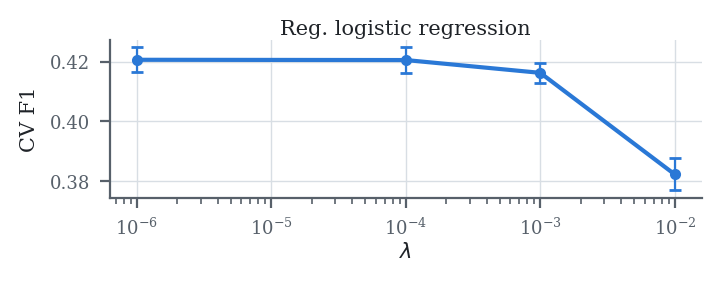

best lambda: 1e-06


In [19]:
def make_reglog_fn(lam, gamma, max_iters):
    def fn(tx_tr, y_tr, tx_val):
        w, _ = impl.reg_logistic_regression(y_tr, tx_tr, lam, np.zeros(tx_tr.shape[1]), max_iters, gamma)
        return predict_logistic(tx_tr, w), predict_logistic(tx_val, w)
    return fn


def plot_cv(xs, means, stds, xlabel, title, log=True, filename=None):
    fig, ax = plt.subplots(figsize=(3.45, 1.25))
    errorbar(ax, xs, means, stds)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel, labelpad=1)
    ax.set_ylabel("CV F1")
    ax.set_title(title, color=INK, pad=2)
    save_and_show(fig, filename or title.lower().replace(" ", "_") + ".pdf")


LOG_ITERS = 1000
reglog_lambdas = [1e-6, 1e-4, 1e-3, 1e-2]
means, stds = [], []
for lam in reglog_lambdas:
    m, s, t = cross_validate(x_train, y01, feature_names, make_reglog_fn(lam, GAMMA_LOG, LOG_ITERS))
    cv_results[f"reg logistic lambda={lam:g}"] = (m, s, t)
    means.append(m)
    stds.append(s)
    print(f"reg logistic lambda={lam:.0e}  F1={m:.4f} ± {s:.4f}  t={t:.3f}")

BEST_LOG_LAMBDA = reglog_lambdas[int(np.argmax(means))]
plot_cv(reglog_lambdas, means, stds, r"$\lambda$", "Reg. logistic regression", filename="reglog_lambda.pdf")
print("best lambda:", BEST_LOG_LAMBDA)

ridge lambda=1e-06  F1=0.4180 ± 0.0049
ridge lambda=1e-04  F1=0.4181 ± 0.0047
ridge lambda=1e-02  F1=0.4190 ± 0.0053
ridge lambda=1e-01  F1=0.4051 ± 0.0037
ridge lambda=1e+00  F1=0.3782 ± 0.0021


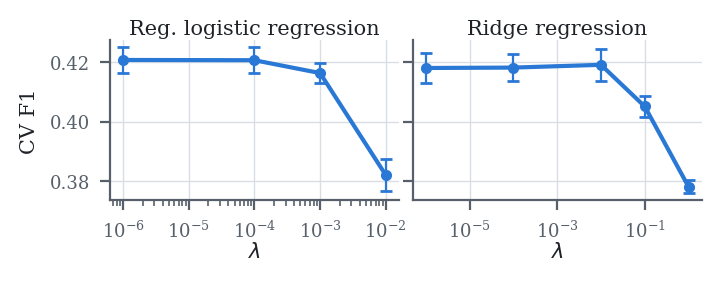

In [20]:
def make_ridge_fn(lam):
    def fn(tx_tr, y_tr, tx_val):
        w, _ = impl.ridge_regression(y_tr, tx_tr, lam)
        return tx_tr @ w, tx_val @ w
    return fn


ridge_lambdas = [1e-6, 1e-4, 1e-2, 1e-1, 1.0]
means, stds = [], []
for lam in ridge_lambdas:
    m, s, t = cross_validate(x_train, y01, feature_names, make_ridge_fn(lam), score_type="linear")
    cv_results[f"ridge lambda={lam:g}"] = (m, s, t)
    means.append(m)
    stds.append(s)
    print(f"ridge lambda={lam:.0e}  F1={m:.4f} ± {s:.4f}")

reglog_means = [cv_results[f"reg logistic lambda={lam:g}"][0] for lam in reglog_lambdas]
reglog_stds = [cv_results[f"reg logistic lambda={lam:g}"][1] for lam in reglog_lambdas]
fig, axes = plt.subplots(1, 2, figsize=(3.45, 1.25), sharey=True)
for ax, title, lams, m_, s_ in [
    (axes[0], "Reg. logistic regression", reglog_lambdas, reglog_means, reglog_stds),
    (axes[1], "Ridge regression", ridge_lambdas, means, stds),
]:
    errorbar(ax, lams, m_, s_)
    ax.set_xscale("log")
    ax.set_title(title, color=INK, pad=2)
    ax.set_xlabel(r"$\lambda$", labelpad=0)
axes[0].set_ylabel("CV F1")
save_and_show(fig, "cv_lambda.pdf")

### Class-weighted logistic regression
Positive samples get a larger weight in the loss. The step size is halved whenever the loss goes up.

In [21]:
def weighted_logistic_regression(y, tx, initial_w, max_iters, gamma, pos_weight=1.0, lambda_=0.0):
    sw = np.where(y == 1, pos_weight, 1.0)
    sw = sw / sw.mean()
    n = len(y)

    w = initial_w.astype(float).copy()
    w_prev, grad_prev, prev_loss = w, None, np.inf
    for _ in range(max_iters):
        z = tx @ w
        loss = np.mean(sw * np.logaddexp(0.0, (1 - 2 * y) * z)) + lambda_ * w @ w
        if not np.isfinite(loss) or loss > prev_loss:
            gamma /= 2
            w = w_prev - gamma * grad_prev
            continue
        grad = tx.T @ (sw * (sigmoid(z) - y)) / n + 2 * lambda_ * w
        w_prev, grad_prev, prev_loss = w, grad, loss
        w = w - gamma * grad

    z = tx @ w
    loss = np.mean(np.logaddexp(0.0, (1 - 2 * y) * z))
    return w, loss


def make_weighted_fn(lam, gamma, max_iters, pos_weight):
    def fn(tx_tr, y_tr, tx_val):
        w, _ = weighted_logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, gamma,
                                            pos_weight=pos_weight, lambda_=lam)
        return predict_logistic(tx_tr, w), predict_logistic(tx_val, w)
    return fn

pos_weight= 1.00  F1=0.4207 ± 0.0042  t=0.193
pos_weight= 3.00  F1=0.4252 ± 0.0045  t=0.417
pos_weight= 5.16  F1=0.4259 ± 0.0049  t=0.557
pos_weight=10.32  F1=0.4265 ± 0.0049  t=0.720


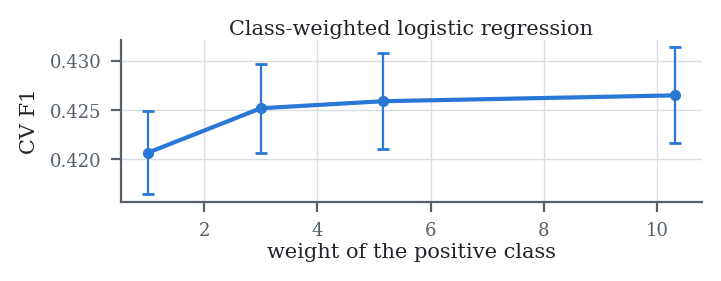

best pos_weight: 10.324762726488352


In [22]:
p = y01.mean()
balanced = (1 - p) / p
pos_weights = [1.0, 3.0, balanced / 2, balanced]

means, stds, ts = [], [], []
for pw in pos_weights:
    fn = make_weighted_fn(BEST_LOG_LAMBDA, GAMMA_LOG, LOG_ITERS, pw)
    m, s, t = cross_validate(x_train, y01, feature_names, fn)
    cv_results[f"weighted logistic pos_weight={pw:.2f}"] = (m, s, t)
    means.append(m)
    stds.append(s)
    ts.append(t)
    print(f"pos_weight={pw:5.2f}  F1={m:.4f} ± {s:.4f}  t={t:.3f}")

BEST_POS_WEIGHT = pos_weights[int(np.argmax(means))]
plot_cv(pos_weights, means, stds, "weight of the positive class", "Class-weighted logistic regression", log=False, filename="pos_weight.pdf")
print("best pos_weight:", BEST_POS_WEIGHT)

## Improvements
- **Newton's method** for logistic regression: the Hessian is small enough to compute, so it converges in a few iterations.
- **Out-of-fold threshold**: the validation predictions of all folds are pooled and one threshold is chosen on them.
- **"Answered none" columns**: a 0/1 column for answers like 88 = none.

In [23]:
def newton_logistic_regression(y, tx, max_iters=15, lambda_=1e-4, pos_weight=1.0, tol=1e-7, chunk=20000):
    n, d = tx.shape
    sw = np.where(y == 1, pos_weight, 1.0)
    sw = sw / sw.mean()

    def loss_fn(w):
        return np.mean(sw * np.logaddexp(0.0, (1 - 2 * y) * (tx @ w))) + lambda_ * w @ w

    w = np.zeros(d)
    loss = loss_fn(w)
    for _ in range(max_iters):
        p = sigmoid(tx @ w)
        grad = tx.T @ (sw * (p - y)) / n + 2 * lambda_ * w
        s = sw * p * (1 - p)
        hessian = 2 * lambda_ * np.eye(d)
        for a in range(0, n, chunk):
            block = tx[a:a + chunk].astype(np.float64)
            hessian += block.T @ (block * s[a:a + chunk, None]) / n
        step = np.linalg.solve(hessian, grad)
        t = 1.0
        new_loss = loss_fn(w - t * step)
        while new_loss > loss - 1e-4 * t * (grad @ step) and t > 1e-4:
            t /= 2
            new_loss = loss_fn(w - t * step)
        w = w - t * step

        converged = loss - new_loss < tol * max(1.0, loss)
        loss = new_loss
        if converged:
            break

    return w, np.mean(np.logaddexp(0.0, (1 - 2 * y) * (tx @ w)))


def make_newton_fn(lam, pos_weight=1.0, max_iters=15):
    def fn(tx_tr, y_tr, tx_val):
        w, _ = newton_logistic_regression(y_tr, tx_tr, max_iters, lam, pos_weight)
        return predict_logistic(tx_tr, w), predict_logistic(tx_val, w)
    return fn


sub = slice(0, 3000)
lam_check = 1e-3
w_newton, _ = newton_logistic_regression(y_tr[sub], tx_tr[sub], 30, lam_check)
w_gd, _ = weighted_logistic_regression(y_tr[sub], tx_tr[sub], np.zeros(D), 20000, GAMMA_LOG, lambda_=lam_check)
reg_loss = lambda w: np.mean(np.logaddexp(0.0, (1 - 2 * y_tr[sub]) * (tx_tr[sub] @ w))) + lam_check * w @ w
print(f"regularized loss  Newton: {reg_loss(w_newton):.6f}  |  GD 20000 steps: {reg_loss(w_gd):.6f}")

regularized loss  Newton: 0.200546  |  GD 20000 steps: 0.200546


In [24]:
def fit_preprocessor_v3(x, y, feature_names, zero_flags=False, **kwargs):
    params = fit_preprocessor(x, y, feature_names, **kwargs)
    zero_flag_columns = []
    if zero_flags:
        idx = {n: j for j, n in enumerate(feature_names)}
        for name, codes in ZERO_CODES.items():
            if name in idx:
                frac = np.isin(x[:, idx[name]], codes).mean()
                if 0 < frac < 1:
                    zero_flag_columns.append((idx[name], codes))
    params["zero_flag_columns"] = zero_flag_columns
    return params


def transform_v3(x, params):
    tx = transform(x, params)
    if not params["zero_flag_columns"]:
        return tx
    flags = np.column_stack([np.isin(x[:, j], codes) for j, codes in params["zero_flag_columns"]])
    return np.concatenate([tx, flags.astype(np.float32)], axis=1)


OOF_CANDIDATES = np.linspace(0.02, 0.98, 193)


def cross_validate_oof(x, y, feature_names, fit_predict_fn, k=K_FOLDS, preproc_kwargs=None):
    preproc_kwargs = preproc_kwargs or {}
    oof_scores = np.zeros(len(y))
    fold_of = np.zeros(len(y), dtype=int)
    for i, (train_idx, val_idx) in enumerate(k_fold_indices(len(y), k)):
        params_f = fit_preprocessor_v3(x[train_idx], y[train_idx], feature_names, **preproc_kwargs)
        tx_tr_f  = transform_v3(x[train_idx], params_f)
        tx_val_f = transform_v3(x[val_idx],   params_f)
        _, oof_scores[val_idx] = fit_predict_fn(tx_tr_f, y[train_idx], tx_val_f)
        fold_of[val_idx] = i
        del tx_tr_f, tx_val_f, params_f
        gc.collect()

    t, _ = best_threshold(y, oof_scores, OOF_CANDIDATES)
    f1s = np.array([f1_score(y[fold_of == i], (oof_scores[fold_of == i] >= t).astype(int)) for i in range(k)])
    return f1s.mean(), f1s.std(), t

In [25]:
experiments = {}


def run_experiment(name, fn, pk):
    m, s, t = cross_validate_oof(x_train, y01, feature_names, fn, preproc_kwargs=pk)
    experiments[name] = (m, s, t)
    return m, s, t


m, s, t = run_experiment("GD weighted logistic (Step 9 best)",
                         make_weighted_fn(BEST_LOG_LAMBDA, GAMMA_LOG, LOG_ITERS, BEST_POS_WEIGHT), {})
print(f"{'GD weighted logistic (Step 9 best)':55s} F1={m:.4f} ± {s:.4f}  t={t:.3f}")

best_lam, best_pw, best_pk = 1e-4, 1.0, {}
best_m, best_s, best_t = run_experiment("Newton logistic", make_newton_fn(best_lam, best_pw), best_pk)
print(f"{'Newton logistic (lambda=1e-4)':55s} F1={best_m:.4f} ± {best_s:.4f}  t={best_t:.3f}")

ideas = [
    ("max_unique_categorical = 20", {"max_unique_categorical": 20}),
    ("max_unique_categorical = 30", {"max_unique_categorical": 30}),
    ("max_unique_categorical = 60", {"max_unique_categorical": 60}),
    ("zero flags (answered none / never)", {"zero_flags": True}),
    ("squares of the 10 most correlated continuous features", {"n_poly": 10}),
    ("missing flags for the dropped columns (50-99% NaN)", {"flag_dropped_max_frac": 0.99}),
    ("max_nan_frac = 0.8", {"max_nan_frac": 0.8}),
]
for name, change in ideas:
    pk = {**best_pk, **change}
    m, s, t = run_experiment(name, make_newton_fn(best_lam, best_pw), pk)
    kept = m > best_m
    print(f"{name:55s} F1={m:.4f} ± {s:.4f}  t={t:.3f}  ->  {'kept' if kept else 'not kept'}")
    if kept:
        best_pk, best_m, best_s, best_t = pk, m, s, t

for lam in [1e-5, 1e-3]:
    m, s, t = run_experiment(f"lambda = {lam:g}", make_newton_fn(lam, best_pw), best_pk)
    kept = m > best_m
    print(f"{f'lambda = {lam:g}':55s} F1={m:.4f} ± {s:.4f}  t={t:.3f}  ->  {'kept' if kept else 'not kept'}")
    if kept:
        best_lam, best_m, best_s, best_t = lam, m, s, t

for pw in [2.0, 4.0]:
    m, s, t = run_experiment(f"pos_weight = {pw:g}", make_newton_fn(best_lam, pw), best_pk)
    kept = m > best_m
    print(f"{f'pos_weight = {pw:g}':55s} F1={m:.4f} ± {s:.4f}  t={t:.3f}  ->  {'kept' if kept else 'not kept'}")
    if kept:
        best_pw, best_m, best_s, best_t = pw, m, s, t

FINAL_PK, FINAL_LAMBDA, FINAL_POS_WEIGHT, FINAL_THRESHOLD = best_pk, best_lam, best_pw, best_t
print(f"\nFINAL: preprocessing={FINAL_PK} lambda={FINAL_LAMBDA:g} pos_weight={FINAL_POS_WEIGHT:g} "
      f"| CV F1={best_m:.4f} ± {best_s:.4f} | threshold={FINAL_THRESHOLD:.3f}")

GD weighted logistic (Step 9 best)                      F1=0.4267 ± 0.0049  t=0.725
Newton logistic (lambda=1e-4)                           F1=0.4269 ± 0.0042  t=0.205
max_unique_categorical = 20                             F1=0.4277 ± 0.0047  t=0.200  ->  kept
max_unique_categorical = 30                             F1=0.4278 ± 0.0043  t=0.200  ->  kept
max_unique_categorical = 60                             F1=0.4276 ± 0.0047  t=0.200  ->  not kept
zero flags (answered none / never)                      F1=0.4281 ± 0.0043  t=0.190  ->  kept
squares of the 10 most correlated continuous features   F1=0.4283 ± 0.0041  t=0.195  ->  kept
missing flags for the dropped columns (50-99% NaN)      F1=0.4297 ± 0.0031  t=0.200  ->  kept
max_nan_frac = 0.8                                      F1=0.4302 ± 0.0028  t=0.195  ->  kept
lambda = 1e-05                                          F1=0.4300 ± 0.0035  t=0.210  ->  not kept
lambda = 0.001                                          F1=0.4265 ± 0.00

## Ablation study (logistic regression)
We change one component at a time and compare with the final logistic model (same folds, out-of-fold threshold).

In [28]:
final_fn = lambda pw=FINAL_POS_WEIGHT: make_newton_fn(FINAL_LAMBDA, pw)

variants = [
    ("no codebook rules (heuristic codes only)", {**FINAL_PK, "use_codebook": False}, final_fn()),
    ("no missing flags", {**FINAL_PK, "use_flags": False}, final_fn()),
    ("no clipping", {**FINAL_PK, "clip": False}, final_fn()),
    ("keep metadata columns", {**FINAL_PK, "drop_metadata": False}, final_fn()),
]
if FINAL_PK.get("max_unique_categorical", 10) != 10:
    variants.append(("max_unique_categorical = 10"  , {**FINAL_PK, "max_unique_categorical": 10}, final_fn()))
if FINAL_PK.get("zero_flags", False):
    variants.append(("no zero flags", {**FINAL_PK, "zero_flags": False}, final_fn()))
if FINAL_PK.get("n_poly", 0) > 0:
    variants.append(("no squared features", {**FINAL_PK, "n_poly": 0}, final_fn()))
if FINAL_POS_WEIGHT != 1.0:
    variants.append(("no class weights", FINAL_PK, final_fn(1.0)))

ablation = [("final pipeline (Newton)", best_m, best_s),
            ("gradient descent, 1000 iters, Step 9 preprocessing",) + experiments["GD weighted logistic (Step 9 best)"][:2]]
for name, pk, fn in variants:
    m, s, _ = cross_validate_oof(x_train, y01, feature_names, fn, preproc_kwargs=pk)
    ablation.append((name, m, s))

print("| Variant | CV F1 (mean ± std) | Δ vs final |")
print("|---|---|---|")
for name, m, s in ablation:
    print(f"| {name} | {m:.4f} ± {s:.4f} | {m - best_m:+.4f} |")

| Variant | CV F1 (mean ± std) | Δ vs final |
|---|---|---|
| final pipeline (Newton) | 0.4302 ± 0.0028 | +0.0000 |
| gradient descent, 1000 iters, Step 9 preprocessing | 0.4267 ± 0.0049 | -0.0035 |
| no codebook rules (heuristic codes only) | 0.4306 ± 0.0032 | +0.0004 |
| no missing flags | 0.4290 ± 0.0035 | -0.0012 |
| no clipping | 0.4299 ± 0.0030 | -0.0002 |
| keep metadata columns | 0.4302 ± 0.0025 | +0.0000 |
| max_unique_categorical = 10 | 0.4297 ± 0.0032 | -0.0005 |
| no zero flags | 0.4299 ± 0.0027 | -0.0003 |
| no squared features | 0.4302 ± 0.0031 | +0.0000 |


## Gradient boosting, interactions and blend
The ablation shows that the preprocessing details barely matter so we try models that can combine features
- **Gradient-boosted trees**, written in NumPy features are cut into 63 bins + one bin for missing values. The number of trees is chosen by early stopping on 10% of the training fold.
- **Pairwise interactions** for the logistic regression: products of the 25 columns most correlated with the label
- **Blend**: a weighted average of the two models' probabilities. The weight and the threshold are chosen on the out-of-fold predictions.
Same folds and same out-of-fold threshold as before, so the numbers are comparable.

In [29]:
N_BINS = 64
NAN_BIN = N_BINS - 1


def learn_heuristic_codes(x, feature_names, use_codebook=True):
    name_to_idx = {n: j for j, n in enumerate(feature_names)}
    codebook_idx = {name_to_idx[n] for n in MISSING_CODES if n in name_to_idx} if use_codebook else set()
    codes = {}
    for j in range(x.shape[1]):
        if j in codebook_idx:
            continue
        non_nan = x[:, j][~np.isnan(x[:, j])]
        if non_nan.size == 0:
            continue
        if feature_names[j].startswith("_") and np.unique(non_nan).size > 50:
            continue
        maxval = non_nan.max()
        if maxval <= 9:
            codes[j] = [7, 9]
        elif maxval <= 99:
            codes[j] = [77, 99]
        elif maxval <= 999:
            codes[j] = [777, 999]
    return codes


def fit_binner(x, feature_names, use_codebook=True, drop_metadata=True):
    feature_names = list(feature_names)
    codes = learn_heuristic_codes(x, feature_names, use_codebook)
    xc = apply_special_codes(x, feature_names, codes, use_codebook)
    metadata_idx = {feature_names.index(n) for n in METADATA_COLUMNS if n in feature_names}

    columns, edges = [], []
    for j in range(xc.shape[1]):
        if drop_metadata and j in metadata_idx:
            continue
        col = xc[:, j]
        non_nan = col[~np.isnan(col)]
        values = np.unique(non_nan)
        if values.size == 0 or (values.size == 1 and non_nan.size == col.size):
            continue
        if values.size <= NAN_BIN:
            e = (values[:-1] + values[1:]) / 2
        else:
            e = np.unique(np.percentile(non_nan, np.linspace(0, 100, NAN_BIN + 1)[1:-1]))
        columns.append(j)
        edges.append(e)
    return {"feature_names": feature_names, "codes": codes, "use_codebook": use_codebook,
            "columns": columns, "edges": edges}


def bin_data(x, binner):
    xc = apply_special_codes(x, binner["feature_names"], binner["codes"], binner["use_codebook"])
    out = np.empty((len(binner["columns"]), len(x)), dtype=np.uint8)
    for k, (j, e) in enumerate(zip(binner["columns"], binner["edges"])):
        col = xc[:, j]
        b = np.searchsorted(e, col, side="right")
        b[np.isnan(col)] = NAN_BIN
        out[k] = b
    return out


def build_tree(xb, g, h, features, max_depth, reg_lambda, min_child_hess):
    n_nodes = 2 ** (max_depth + 1) - 1
    split = np.zeros(n_nodes, dtype=bool)
    feat = np.zeros(n_nodes, dtype=np.int64)
    thr = np.zeros(n_nodes, dtype=np.int64)
    nan_left = np.zeros(n_nodes, dtype=bool)

    n = xb.shape[1]
    node = np.zeros(n, dtype=np.int64)
    active = np.arange(n)
    score = lambda G, H: G * G / (H + reg_lambda)

    hg_parent = hh_parent = None
    for depth in range(max_depth):
        if active.size == 0:
            break
        first, width = 2 ** depth - 1, 2 ** depth
        local = node[active] - first

        if depth == 0:
            rows, key, n_hist = active, local * N_BINS, 1
        else:
            is_left = local % 2 == 0
            rows, key, n_hist = active[is_left], (local[is_left] // 2) * N_BINS, width // 2
        g_r, h_r = g[rows], h[rows]
        xr = xb[:, rows]
        hg_new = np.empty((n_hist, len(features), N_BINS))
        hh_new = np.empty((n_hist, len(features), N_BINS))
        for k, f in enumerate(features):
            kf = key + xr[f]
            hg_new[:, k, :] = np.bincount(kf, weights=g_r, minlength=n_hist * N_BINS).reshape(n_hist, N_BINS)
            hh_new[:, k, :] = np.bincount(kf, weights=h_r, minlength=n_hist * N_BINS).reshape(n_hist, N_BINS)
        if depth == 0:
            hg, hh = hg_new, hh_new
        else:
            parent_split = split[2 ** (depth - 1) - 1: first][:, None, None]
            hg = np.empty((width, len(features), N_BINS))
            hh = np.empty((width, len(features), N_BINS))
            hg[0::2], hh[0::2] = hg_new, hh_new
            hg[1::2] = np.where(parent_split, hg_parent - hg_new, 0.0)
            hh[1::2] = np.where(parent_split, hh_parent - hh_new, 0.0)
        hg_parent, hh_parent = hg, hh

        G = hg[:, 0, :].sum(axis=1)[:, None, None]
        H = hh[:, 0, :].sum(axis=1)[:, None, None]
        cg, ch = np.cumsum(hg[:, :, :NAN_BIN], axis=2), np.cumsum(hh[:, :, :NAN_BIN], axis=2)
        ng, nh = hg[:, :, NAN_BIN:], hh[:, :, NAN_BIN:]

        gains = np.empty(cg.shape + (2,))
        for side, (GL, HL) in enumerate([(cg, ch), (cg + ng, ch + nh)]):
            HR = H - HL
            gain = score(GL, HL) + score(G - GL, HR) - score(G, H)
            gain[(HL < min_child_hess) | (HR < min_child_hess)] = -np.inf
            gains[..., side] = gain

        flat = gains.reshape(width, -1)
        best = flat.argmax(axis=1)
        best_gain = flat[np.arange(width), best]
        k_best, t_best, side_best = np.unravel_index(best, cg.shape[1:] + (2,))
        for i in np.flatnonzero(best_gain > 1e-12):
            nd = first + i
            split[nd] = True
            feat[nd] = features[k_best[i]]
            thr[nd] = t_best[i]
            nan_left[nd] = side_best[i] == 1

        go = split[node[active]]
        active = active[go]
        nd = node[active]
        b = xb[feat[nd], active]
        left = np.where(b == NAN_BIN, nan_left[nd], b <= thr[nd])
        node[active] = 2 * nd + 1 + (~left)

    G_leaf = np.bincount(node, weights=g, minlength=n_nodes)
    H_leaf = np.bincount(node, weights=h, minlength=n_nodes)
    value = -G_leaf / (H_leaf + reg_lambda)
    return {"split": split, "feat": feat, "thr": thr, "nan_left": nan_left, "value": value}


def predict_tree(tree, xb):
    node = np.zeros(xb.shape[1], dtype=np.int64)
    idx = np.arange(xb.shape[1])
    while idx.size > 0:
        nd = node[idx]
        go = tree["split"][nd]
        idx, nd = idx[go], nd[go]
        if idx.size == 0:
            break
        b = xb[tree["feat"][nd], idx]
        left = np.where(b == NAN_BIN, tree["nan_left"][nd], b <= tree["thr"][nd])
        node[idx] = 2 * nd + 1 + (~left)
    return tree["value"][node]


def gbdt_fit(xb, y, xb_valid=None, y_valid=None, n_trees=500, learning_rate=0.1, max_depth=5,
             reg_lambda=1.0, min_child_hess=5.0, subsample=0.5, colsample=0.8, pos_weight=1.0,
             early_stopping=50, seed=SEED):
    rng = np.random.RandomState(seed)
    n_feat, n = xb.shape
    sw = np.where(y == 1, pos_weight, 1.0)
    p0 = np.clip(np.sum(sw * y) / np.sum(sw), 1e-6, 1 - 1e-6)
    base = np.log(p0 / (1 - p0))

    raw = np.full(n, base)
    has_valid = xb_valid is not None
    raw_valid = np.full(xb_valid.shape[1], base) if has_valid else None
    trees, best_loss, best_iter = [], np.inf, 0

    for t in range(n_trees):
        p = sigmoid(raw)
        g, h = sw * (p - y), sw * p * (1 - p)
        rows = np.sort(rng.choice(n, int(subsample * n), replace=False))
        features = np.sort(rng.choice(n_feat, max(1, int(colsample * n_feat)), replace=False))
        tree = build_tree(xb[:, rows], g[rows], h[rows], features, max_depth, reg_lambda, min_child_hess)
        tree["value"] *= learning_rate
        trees.append(tree)
        raw += predict_tree(tree, xb)

        if has_valid:
            raw_valid += predict_tree(tree, xb_valid)
            loss = np.mean(np.logaddexp(0.0, (1 - 2 * y_valid) * raw_valid))
            if loss < best_loss - 1e-7:
                best_loss, best_iter = loss, t + 1
            elif t + 1 - best_iter >= early_stopping:
                break

    if has_valid:
        trees = trees[:best_iter]
    return {"base": base, "trees": trees}


def gbdt_predict_proba(model, xb):
    raw = np.full(xb.shape[1], model["base"])
    for tree in model["trees"]:
        raw += predict_tree(tree, xb)
    return sigmoid(raw)


rng_check = np.random.RandomState(0)
Xc = rng_check.rand(20000, 3)
Xc[rng_check.rand(20000) < 0.2, 2] = np.nan
zc = 4 * ((Xc[:, 0] > 0.5) ^ (Xc[:, 1] > 0.5)) - 2 + 2 * np.isnan(Xc[:, 2])
yc = (rng_check.rand(20000) < sigmoid(zc)).astype(float)
binner_c = fit_binner(Xc[:15000], ["c0", "c1", "c2"], use_codebook=False)
xb_c = bin_data(Xc, binner_c)
model_c = gbdt_fit(xb_c[:, :13000], yc[:13000], xb_c[:, 13000:15000], yc[13000:15000], n_trees=300)
p_c = gbdt_predict_proba(model_c, xb_c[:, 15000:])
logloss = lambda y, p: np.mean(-(y * np.log(p) + (1 - y) * np.log(1 - p)))
print(f"XOR check: GBDT logloss {logloss(yc[15000:], p_c):.3f} | true model {logloss(yc[15000:], sigmoid(zc[15000:])):.3f} "
      f"| constant {logloss(yc[15000:], np.full(5000, yc.mean())):.3f}")
assert logloss(yc[15000:], p_c) < logloss(yc[15000:], sigmoid(zc[15000:])) + 0.03
del Xc, zc, yc, xb_c, model_c, p_c

XOR check: GBDT logloss 0.377 | true model 0.366 | constant 0.690


In [30]:
import time

LOGISTIC_PK = {"max_unique_categorical": 30, "zero_flags": True, "n_poly": 10,
               "flag_dropped_max_frac": 0.99, "max_nan_frac": 0.8}
LOGISTIC_LAMBDA, LOGISTIC_POS_WEIGHT = 1e-4, 1.0

GBDT_PARAMS = dict(n_trees=1000, learning_rate=0.1, max_depth=5, reg_lambda=1.0, min_child_hess=5.0,
                   subsample=0.5, colsample=0.5, early_stopping=50)


def oof_predict(x, y, fit_predict_raw, k=K_FOLDS):
    oof_scores = np.zeros(len(y))
    fold_of = np.zeros(len(y), dtype=int)
    infos = []
    for i, (train_idx, val_idx) in enumerate(k_fold_indices(len(y), k)):
        oof_scores[val_idx], info = fit_predict_raw(x[train_idx], y[train_idx], x[val_idx])
        fold_of[val_idx] = i
        infos.append(info)
        gc.collect()
    return oof_scores, fold_of, infos


def f1_from_oof(y, oof_scores, fold_of):
    t, _ = best_threshold(y, oof_scores, OOF_CANDIDATES)
    f1s = np.array([f1_score(y[fold_of == i], (oof_scores[fold_of == i] >= t).astype(int))
                    for i in np.unique(fold_of)])
    return f1s.mean(), f1s.std(), t


def fit_interactions(tx, y, k):
    yc = y - y.mean()
    cols = tx[:, 1:]
    corr = np.abs(cols.T @ yc) / len(y) / (cols.std(axis=0) * yc.std() + 1e-12)
    top = 1 + np.argsort(corr)[::-1][:k]
    pairs = np.array([(a, b) for i, a in enumerate(top) for b in top[i + 1:]])
    prods = tx[:, pairs[:, 0]] * tx[:, pairs[:, 1]]
    return {"pairs": pairs, "mean": prods.mean(axis=0), "std": prods.std(axis=0) + 1e-6}


def add_interactions(tx, inter):
    prods = (tx[:, inter["pairs"][:, 0]] * tx[:, inter["pairs"][:, 1]] - inter["mean"]) / inter["std"]
    return np.concatenate([tx, prods.astype(np.float32)], axis=1)


def make_logistic_raw(n_interact=0):
    def fn(x_tr, y_tr, x_val):
        params_f = fit_preprocessor_v3(x_tr, y_tr, feature_names, **LOGISTIC_PK)
        tx_tr_f, tx_val_f = transform_v3(x_tr, params_f), transform_v3(x_val, params_f)
        if n_interact > 0:
            inter = fit_interactions(tx_tr_f, y_tr, n_interact)
            tx_tr_f, tx_val_f = add_interactions(tx_tr_f, inter), add_interactions(tx_val_f, inter)
        w, _ = newton_logistic_regression(y_tr, tx_tr_f, 15, LOGISTIC_LAMBDA, LOGISTIC_POS_WEIGHT)
        return predict_logistic(tx_val_f, w), tx_tr_f.shape[1]
    return fn


def make_gbdt_raw(**overrides):
    params_gb = {**GBDT_PARAMS, **overrides}
    def fn(x_tr, y_tr, x_val):
        binner = fit_binner(x_tr, feature_names)
        xb_tr, xb_val = bin_data(x_tr, binner), bin_data(x_val, binner)
        perm = np.random.RandomState(SEED).permutation(len(y_tr))
        n_es = len(y_tr) // 10
        es, fit = np.sort(perm[:n_es]), np.sort(perm[n_es:])
        model = gbdt_fit(xb_tr[:, fit], y_tr[fit], xb_tr[:, es], y_tr[es], **params_gb)
        return gbdt_predict_proba(model, xb_val), len(model["trees"])
    return fn


oof = {}
results10b = {}
GBDT_CONFIGS = {}


def record(name, fn):
    start = time.time()
    scores, fold_of, infos = oof_predict(x_train, y01, fn)
    m, s, t = f1_from_oof(y01, scores, fold_of)
    oof[name], results10b[name] = scores, (m, s, t, infos)
    print(f"{name:45s} F1={m:.4f} ± {s:.4f}  t={t:.3f}  info={infos}  ({(time.time() - start) / 60:.1f} min)")
    return fold_of


FOLD_OF = record("Newton logistic (submitted)", make_logistic_raw())

Newton logistic (submitted)                   F1=0.4302 ± 0.0028  t=0.195  info=[757, 755, 755]  (5.6 min)


In [31]:
record("Newton logistic + interactions (top 25)", make_logistic_raw(n_interact=25))

for name, overrides in [("GBDT depth 5", {}), ("GBDT depth 4", {"max_depth": 4}), ("GBDT depth 6", {"max_depth": 6})]:
    GBDT_CONFIGS[name] = overrides
    record(name, make_gbdt_raw(**overrides))

Newton logistic + interactions (top 25)       F1=0.4311 ± 0.0031  t=0.205  info=[1057, 1055, 1055]  (8.9 min)
GBDT depth 5                                  F1=0.4414 ± 0.0028  t=0.210  info=[121, 130, 222]  (8.9 min)
GBDT depth 4                                  F1=0.4421 ± 0.0035  t=0.220  info=[183, 171, 216]  (9.9 min)
GBDT depth 6                                  F1=0.4418 ± 0.0028  t=0.210  info=[127, 124, 149]  (16.5 min)


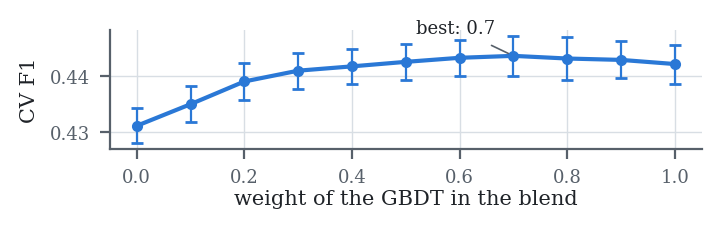

| Model | CV F1 (mean ± std) | threshold |
|---|---|---|
| Newton logistic (submitted) | 0.4302 ± 0.0028 | 0.195 |
| Newton logistic + interactions (top 25) | 0.4311 ± 0.0031 | 0.205 |
| GBDT depth 5 | 0.4414 ± 0.0028 | 0.210 |
| GBDT depth 4 | 0.4421 ± 0.0035 | 0.220 |
| GBDT depth 6 | 0.4418 ± 0.0028 | 0.210 |
| Blend 0.7 x GBDT depth 4 + 0.3 x Newton logistic + interactions (top 25) | 0.4436 ± 0.0036 | 0.225 |

FINAL: blend weight=0.7 gbdt=GBDT depth 4 {'max_depth': 4} logistic=Newton logistic + interactions (top 25) threshold=0.225 | trees per fold=[183, 171, 216]


In [32]:
best_gb = max(GBDT_CONFIGS, key=lambda n: results10b[n][0])
best_lr = max([n for n in results10b if n.startswith("Newton")], key=lambda n: results10b[n][0])

weights = np.linspace(0, 1, 11)
blend_scores = []
for wgt in weights:
    blend_scores.append(f1_from_oof(y01, wgt * oof[best_gb] + (1 - wgt) * oof[best_lr], FOLD_OF))
means = np.array([b[0] for b in blend_scores])
stds = np.array([b[1] for b in blend_scores])

fig, ax = plt.subplots(figsize=(3.45, 0.98))
errorbar(ax, weights, means, stds)
best_i = int(np.argmax(means))
ax.annotate(f"best: {weights[best_i]:.1f}", (weights[best_i], means[best_i]),
            xytext=(weights[best_i] - 0.18, means[best_i] + 0.004), fontsize=6.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
ax.set_xlabel("weight of the GBDT in the blend", labelpad=1)
ax.set_ylabel("CV F1")
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
save_and_show(fig, "blend.pdf")
BLEND_WEIGHT = float(weights[int(np.argmax(means))])
FINAL_F1, FINAL_STD, FINAL_THRESHOLD = blend_scores[int(np.argmax(means))]

print("| Model | CV F1 (mean ± std) | threshold |")
print("|---|---|---|")
for name, (m, s, t, _) in results10b.items():
    print(f"| {name} | {m:.4f} ± {s:.4f} | {t:.3f} |")
print(f"| Blend {BLEND_WEIGHT:.1f} x {best_gb} + {1 - BLEND_WEIGHT:.1f} x {best_lr} | {FINAL_F1:.4f} ± {FINAL_STD:.4f} | {FINAL_THRESHOLD:.3f} |")
print(f"\nFINAL: blend weight={BLEND_WEIGHT:.1f} gbdt={best_gb} {GBDT_CONFIGS[best_gb]} logistic={best_lr} "
      f"threshold={FINAL_THRESHOLD:.3f} | trees per fold={results10b[best_gb][3]}")

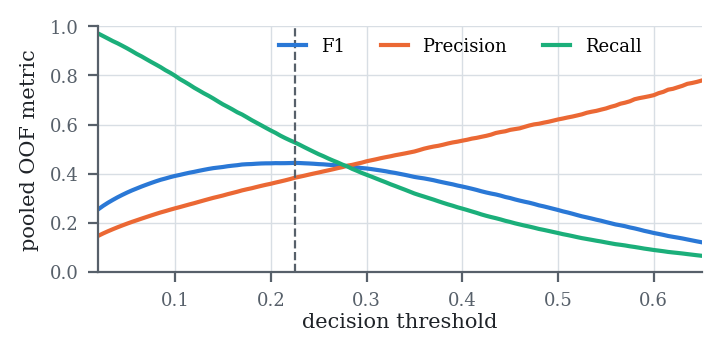

threshold 0.225: F1 0.4436, precision 38.3%, recall 52.7%, TP 15272, FP 24602, FN 13703
threshold 0.5: F1 0.2517


In [33]:
blend_oof = BLEND_WEIGHT * oof[best_gb] + (1 - BLEND_WEIGHT) * oof[best_lr]


def pooled_metrics(t):
    pred = blend_oof >= t
    tp = int(np.sum(pred & (y01 == 1)))
    fp = int(np.sum(pred & (y01 == 0)))
    fn = int(np.sum(~pred & (y01 == 1)))
    return 2 * tp / max(2 * tp + fp + fn, 1), tp / max(tp + fp, 1), tp / max(tp + fn, 1), tp, fp, fn


grid = np.linspace(0.02, 0.65, 127)
curves = np.array([pooled_metrics(t)[:3] for t in grid])
fig, ax = plt.subplots(figsize=(3.45, 1.6))
for k, (name, color) in enumerate([("F1", BLUE), ("Precision", ORANGE), ("Recall", GREEN)]):
    ax.plot(grid, curves[:, k], color=color, linewidth=1.5, label=name)
ax.axvline(FINAL_THRESHOLD, color=MUTED, linestyle="--", linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.6, 1.02), ncol=3, frameon=False, fontsize=6.5, handlelength=1.5)
ax.set_xlim(grid[0], grid[-1])
ax.set_ylim(0, 1)
ax.set_xlabel("decision threshold", labelpad=1)
ax.set_ylabel("pooled OOF metric")
save_and_show(fig, "threshold.pdf")

f1_at_t, precision_at_t, recall_at_t, n_tp, n_fp, n_fn = pooled_metrics(FINAL_THRESHOLD)
print(f"threshold {FINAL_THRESHOLD:.3f}: F1 {f1_at_t:.4f}, precision {precision_at_t:.1%}, "
      f"recall {recall_at_t:.1%}, TP {n_tp}, FP {n_fp}, FN {n_fn}")
print(f"threshold 0.5: F1 {pooled_metrics(0.5)[0]:.4f}")

### Ablation study (gradient boosting)

In [34]:
RUN_GBDT_ABLATION = True

if RUN_GBDT_ABLATION:
    base_overrides = GBDT_CONFIGS[best_gb]

    def make_gbdt_variant(use_codebook=True, drop_metadata=True, **overrides):
        params_gb = {**GBDT_PARAMS, **base_overrides, **overrides}
        def fn(x_tr, y_tr, x_val):
            binner = fit_binner(x_tr, feature_names, use_codebook=use_codebook, drop_metadata=drop_metadata)
            xb_tr, xb_val = bin_data(x_tr, binner), bin_data(x_val, binner)
            perm = np.random.RandomState(SEED).permutation(len(y_tr))
            n_es = len(y_tr) // 10
            es, fit = np.sort(perm[:n_es]), np.sort(perm[n_es:])
            model = gbdt_fit(xb_tr[:, fit], y_tr[fit], xb_tr[:, es], y_tr[es], **params_gb)
            return gbdt_predict_proba(model, xb_val), len(model["trees"])
        return fn

    gb_ablation = [(best_gb, results10b[best_gb][0], results10b[best_gb][1])]
    for name, kwargs in [("no codebook rules", {"use_codebook": False}),
                         ("keep metadata columns", {"drop_metadata": False}),
                         ("no row / feature subsampling", {"subsample": 1.0, "colsample": 1.0})]:
        scores, fold_of, _ = oof_predict(x_train, y01, make_gbdt_variant(**kwargs))
        m, s, _ = f1_from_oof(y01, scores, fold_of)
        gb_ablation.append((name, m, s))

    print("| GBDT variant | CV F1 (mean ± std) | Δ |")
    print("|---|---|---|")
    for name, m, s in gb_ablation:
        print(f"| {name} | {m:.4f} ± {s:.4f} | {m - gb_ablation[0][1]:+.4f} |")

| GBDT variant | CV F1 (mean ± std) | Δ |
|---|---|---|
| GBDT depth 4 | 0.4421 ± 0.0035 | +0.0000 |
| no codebook rules | 0.4417 ± 0.0025 | -0.0005 |
| keep metadata columns | 0.4422 ± 0.0024 | +0.0001 |
| no row / feature subsampling | 0.4425 ± 0.0025 | +0.0004 |


## Final model and submission (AIcrowd F1 0.455)

In [35]:
for name in ["tx_tr", "tx_val", "tx_te", "tx_full", "tx_test"]:
    globals().pop(name, None)
gc.collect()

p_test = np.zeros(len(x_test))

if BLEND_WEIGHT > 0:
    n_trees_final = int(round(np.mean(results10b[best_gb][3]) * 1.1))
    binner_full = fit_binner(x_train, feature_names)
    xb_full, xb_test = bin_data(x_train, binner_full), bin_data(x_test, binner_full)
    params_final = {**GBDT_PARAMS, **GBDT_CONFIGS[best_gb], "n_trees": n_trees_final}
    gb_final = gbdt_fit(xb_full, y01, **params_final)
    p_test += BLEND_WEIGHT * gbdt_predict_proba(gb_final, xb_test)
    print("GBDT trees:", n_trees_final)
    del xb_full, xb_test

if BLEND_WEIGHT < 1:
    params_full = fit_preprocessor_v3(x_train, y01, feature_names, **LOGISTIC_PK)
    tx_full, tx_test = transform_v3(x_train, params_full), transform_v3(x_test, params_full)
    if "interactions" in best_lr:
        inter_full = fit_interactions(tx_full, y01, 25)
        tx_full, tx_test = add_interactions(tx_full, inter_full), add_interactions(tx_test, inter_full)
    w_final, _ = newton_logistic_regression(y01, tx_full, 15, LOGISTIC_LAMBDA, LOGISTIC_POS_WEIGHT)
    p_test += (1 - BLEND_WEIGHT) * predict_logistic(tx_test, w_final)
    del tx_full, tx_test

pred01 = (p_test >= FINAL_THRESHOLD).astype(int)
y_pred_sub = np.where(pred01 == 1, 1, -1)

assert set(np.unique(y_pred_sub)) <= {-1, 1}
assert len(y_pred_sub) == len(test_ids)
print("predicted positive rate:", (y_pred_sub == 1).mean())
create_csv_submission(test_ids, y_pred_sub, "submission_v4.csv")
print("written submission_v4.csv | CV F1 of this model:", round(FINAL_F1, 4))

gb_params_used = {k: v for k, v in {**GBDT_PARAMS, **GBDT_CONFIGS[best_gb]}.items()
                  if k not in ("n_trees", "early_stopping")}
print("\nCONFIG = " + repr({
    "logistic_pk": LOGISTIC_PK,
    "logistic_lambda": LOGISTIC_LAMBDA,
    "logistic_pos_weight": LOGISTIC_POS_WEIGHT,
    "logistic_interactions": 25 if "interactions" in best_lr else 0,
    "blend_weight": BLEND_WEIGHT,
    "gbdt_params": gb_params_used,
    "gbdt_trees": n_trees_final if BLEND_WEIGHT > 0 else 0,
    "threshold": float(FINAL_THRESHOLD),
}))

GBDT trees: 209
predicted positive rate: 0.12241838012781246
written submission_v4.csv | CV F1 of this model: 0.4436

CONFIG = {'logistic_pk': {'max_unique_categorical': 30, 'zero_flags': True, 'n_poly': 10, 'flag_dropped_max_frac': 0.99, 'max_nan_frac': 0.8}, 'logistic_lambda': 0.0001, 'logistic_pos_weight': 1.0, 'logistic_interactions': 25, 'blend_weight': 0.7000000000000001, 'gbdt_params': {'learning_rate': 0.1, 'max_depth': 4, 'reg_lambda': 1.0, 'min_child_hess': 5.0, 'subsample': 0.5, 'colsample': 0.5}, 'gbdt_trees': 209, 'threshold': 0.225}
